# Подбор числа кластеров методом локтя

Проверим, можно ли по кривой инерции восстановить число групп в искусственном наборе данных.

## 1. Данные

Сгенерируем 300 точек с двумя признаками вокруг трёх центров. K-means получает только координаты точек.

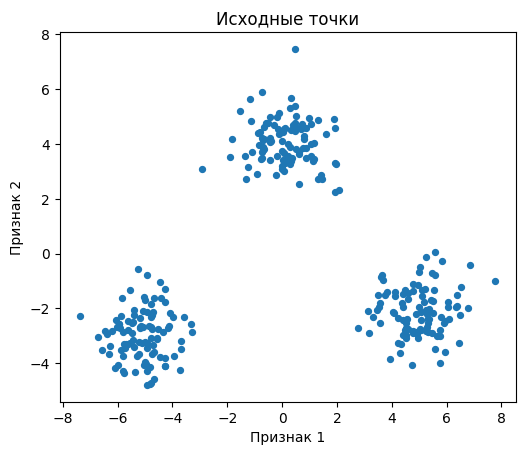

In [3]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

X, _ = make_blobs(
    n_samples=300,
    centers=[(-5, -3), (0, 4), (5, -2)],
    cluster_std=0.9,
    random_state=42,
)

fig, ax = plt.subplots()
ax.scatter(X[:, 0], X[:, 1], s=18)
ax.set(xlabel="Признак 1", ylabel="Признак 2", title="Исходные точки")
ax.set_aspect("equal")
plt.show()

## 2. Кривая инерции

Для каждого числа кластеров обучим K-means и запишем инерцию — сумму квадратов расстояний от точек до центров их кластеров. Используем по 10 начальных разбиений на каждое значение k, чтобы уменьшить влияние инициализации.

k= 1:   8444.2
k= 2:   3520.6
k= 3:    454.6
k= 4:    399.0
k= 5:    344.3
k= 6:    293.3
k= 7:    253.2
k= 8:    220.9
k= 9:    189.8
k=10:    175.8


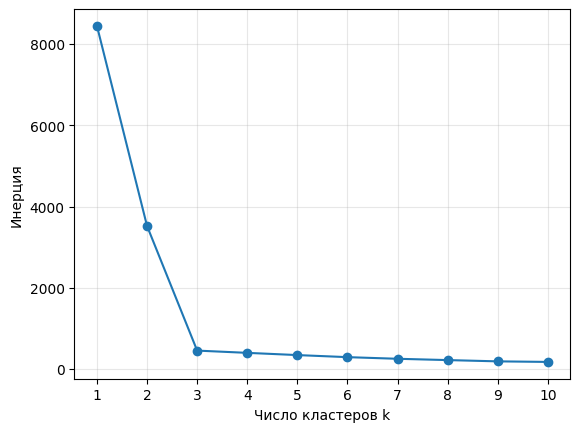

In [4]:
cluster_counts = range(1, 11)
models = []
for k in cluster_counts:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    models.append(model.fit(X))

inertias = [model.inertia_ for model in models]
for k, inertia in zip(cluster_counts, inertias):
    print(f"k={k:2}: {inertia:8.1f}")

fig, ax = plt.subplots()
ax.plot(cluster_counts, inertias, marker="o")
ax.set(xlabel="Число кластеров k", ylabel="Инерция", xticks=list(cluster_counts))
ax.grid(alpha=0.3)
plt.show()

## 3. Выбор числа кластеров

При переходе от двух кластеров к трём инерция падает примерно на 3066,0. При добавлении четвёртого кластера она снижается ещё на 55,6. Кривая заметно выравнивается при $k=3$, поэтому выбираем три кластера.

Покажем разбиение для выбранного значения. Цвет обозначает кластер, крестик — его центр.

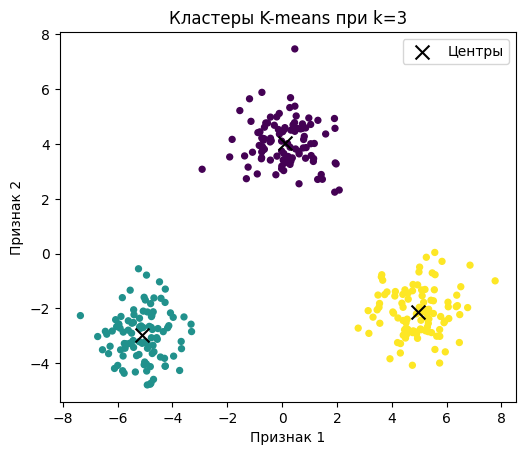

In [5]:
selected_k = 3
selected_model = models[cluster_counts.index(selected_k)]
centers = selected_model.cluster_centers_

fig, ax = plt.subplots()
ax.scatter(X[:, 0], X[:, 1], c=selected_model.labels_, cmap="viridis", s=18)
ax.scatter(centers[:, 0], centers[:, 1], marker="x", c="black", s=100, label="Центры")
ax.set(xlabel="Признак 1", ylabel="Признак 2", title=f"Кластеры K-means при k={selected_k}")
ax.set_aspect("equal")
ax.legend()
plt.show()

## Вывод

Метод локтя указал на три кластера. Это совпадает с числом групп, заданным при генерации, а на графике разбиения у каждого облака точек виден свой центр. На данных с перекрывающимися группами изгиб может быть менее выраженным.